# El error, descompuesto

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 3, unidad 1 · Genera la figura de la lámina «Con números»

---

La clase afirma que el error esperado de un modelo se parte en tres sumandos
—sesgo al cuadrado, varianza y ruido irreducible— y que al aumentar la capacidad
el primero baja y el segundo sube.

Aquí lo medimos. El experimento es el de la lámina: repetir el estudio muchas
veces con muestras independientes de la misma distribución, algo que en la vida
real no se puede hacer y que en simulación sí.

## El diseño

Es el de Bishop (2006), §3.2, figura 3.5, con su mismo tamaño de muestra:

> *«There are L = 100 data sets, each having N = 25 data points, and there are 24
> Gaussian basis functions in the model so that the total number of parameters is
> M = 25 including the bias parameter.»*

| | |
|---|---|
| Función verdadera | $f(x)=\operatorname{sen}(2\pi x)$, la de Bishop §1.1 y la de la clase 1 |
| Ruido | $\varepsilon\sim N(0,\ 0{,}25^2)$, de modo que $\sigma^2 = 0{,}0625$ |
| Réplicas | 3000 muestras independientes de $n=25$ |
| Modelo | 24 funciones base gaussianas más el sesgo: **25 parámetros, siempre** |
| Capacidad | se controla con $\lambda$, el peso de la regularización de cresta |
| Punto de evaluación | $x_0 = 0{,}35$ |

**Lo que se barre es $\lambda$, no el número de parámetros.** Esa es la diferencia
que conviene notar: el modelo tiene 25 parámetros en todas las corridas, de
principio a fin, y aun así el error recorre la curva en U completa. Es la
demostración medida de lo que afirma la lámina «Capacidad»: **la capacidad no es
el número de parámetros**. Y es, además, el mecanismo de la semana 4.

La identidad que vamos a comprobar numéricamente es

$$\mathbb{E}\bigl[(y-\hat h_S(x_0))^2\bigr]=
\bigl(f(x_0)-\bar h(x_0)\bigr)^2+
\mathbb{E}\bigl[(\hat h_S(x_0)-\bar h(x_0))^2\bigr]+
\sigma^2$$

Si la suma de los tres términos no reproduce el error total, algo está mal —y la
sección 8 falla ruidosamente.

## Referencias

- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer.
  §1.1 para el ejemplo de $\operatorname{sen}(2\pi x)$; §3.2 y las figuras 3.5 y
  3.6 para este experimento.
- Geman, S., Bienenstock, E., & Doursat, R. (1992). Neural networks and the
  bias/variance dilemma. *Neural Computation*, 4(1), 1–58. El artículo de origen.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical
  Learning* (2ª ed.), §7.1–7.3. La lectura de apoyo de la semana.

## 1. Entorno

Se declara para que un tercero pueda reproducir el resultado exacto. Es el ítem 2
de la lista de cotejo de los talleres.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python     ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)

Python      3.12.14 | Darwin arm64
numpy       2.2.6
matplotlib  3.10.9


## 2. Parámetros

Todo lo que gobierna el resultado está aquí, con nombre. `N_REPLICAS = 3000` fija
la precisión con que se mide el sesgo: el promedio sobre réplicas tiene su propia
incertidumbre, $\operatorname{Var}/R$, y esa cantidad es un piso por debajo del
cual el sesgo medido ya no sería sesgo sino ruido de simulación. La sección 8
verifica que estamos cómodamente por encima de ese piso.

In [2]:
SEMILLA = 3
N_REPLICAS = 3000           # muestras independientes de la misma distribución
N_ENTRENAMIENTO = 25        # tamaño de cada muestra; el N de Bishop
SIGMA = 0.25                # desviación del ruido; sigma**2 es el piso
X0 = 0.35                   # punto donde se descompone el error

N_BASES = 24                # funciones gaussianas; con el sesgo, 25 parámetros
ANCHO_BASE = 0.1            # s de cada gaussiana
CENTROS = np.linspace(0, 1, N_BASES)

# La capacidad se recorre con lambda, no con el numero de parametros.
LOG_LAMBDAS = np.arange(-6, 7, 1.0)
LAMBDAS = np.exp(LOG_LAMBDAS)

def f_verdadera(x):
    """La función que genera los datos. En un problema real, desconocida."""
    return np.sin(2 * np.pi * x)

def base(x):
    """Diseño: una columna de unos (el sesgo) y 24 gaussianas."""
    x = np.atleast_1d(x)
    gauss = np.exp(-(x[:, None] - CENTROS[None, :]) ** 2 / (2 * ANCHO_BASE ** 2))
    return np.hstack([np.ones((x.size, 1)), gauss])

print(f"Piso de ruido  sigma^2 = {SIGMA**2:.4f}")
print(f"f(x0) = {f_verdadera(X0):.4f}")
print(f"Parámetros del modelo: {N_BASES + 1} (fijos en todo el barrido)")
print(f"lambda: de exp({LOG_LAMBDAS[0]:.0f}) a exp({LOG_LAMBDAS[-1]:.0f}), "
      f"{len(LAMBDAS)} valores")

Piso de ruido  sigma^2 = 0.0625
f(x0) = 0.8090
Parámetros del modelo: 25 (fijos en todo el barrido)
lambda: de exp(-6) a exp(6), 13 valores


## 3. Protocolo

**Cada réplica es un estudio completo e independiente.** Se genera su propia
muestra, se ajusta el modelo con cada valor de $\lambda$, y se registra la
predicción en $x_0$. Nada se comparte entre réplicas salvo la función verdadera y
el nivel de ruido.

El ajuste es regresión de cresta, la fórmula cerrada que se ve en la semana 4:

$$\hat w_\lambda = \bigl(\Phi^\top\Phi + \lambda I\bigr)^{-1}\Phi^\top y$$

Con $\lambda$ grande los coeficientes se aplastan contra cero y el modelo es casi
una constante; con $\lambda$ pequeño quedan libres y las 25 funciones base
persiguen los 25 puntos. **La familia es la misma en ambos extremos.** Lo que
cambia es cuánta de ella el ajuste está dispuesto a usar.

No hay conjunto de prueba aquí porque no hace falta: conocemos $f$, así que el
sesgo se calcula exactamente y no se estima. Esa es la ventaja de la simulación,
y también la razón de que este cuaderno **no** sea un protocolo de evaluación
—los protocolos con datos reales son la unidad 3.

In [3]:
rng = np.random.default_rng(SEMILLA)

# predicciones[r, j] = predicción en x0 del modelo ajustado con lambda LAMBDAS[j]
#                      sobre la réplica r
predicciones = np.empty((N_REPLICAS, len(LAMBDAS)))
base_x0 = base(X0)
identidad = np.eye(N_BASES + 1)

for r in range(N_REPLICAS):
    x = np.sort(rng.uniform(0, 1, N_ENTRENAMIENTO))
    y = f_verdadera(x) + rng.normal(0, SIGMA, N_ENTRENAMIENTO)
    Phi = base(x)
    gram, proy = Phi.T @ Phi, Phi.T @ y
    for j, lam in enumerate(LAMBDAS):
        w = np.linalg.solve(gram + lam * identidad, proy)
        predicciones[r, j] = base_x0 @ w

print(f"Predicciones registradas: {predicciones.shape[0]} réplicas "
      f"x {predicciones.shape[1]} valores de lambda")

/var/folders/tn/wmtf6rw515q62k6zgxrqp3xh0000gn/T/ipykernel_49669/1865798403.py:13: RuntimeWarning: divide by zero encountered in matmul
  gram, proy = Phi.T @ Phi, Phi.T @ y
/var/folders/tn/wmtf6rw515q62k6zgxrqp3xh0000gn/T/ipykernel_49669/1865798403.py:13: RuntimeWarning: overflow encountered in matmul
  gram, proy = Phi.T @ Phi, Phi.T @ y
/var/folders/tn/wmtf6rw515q62k6zgxrqp3xh0000gn/T/ipykernel_49669/1865798403.py:13: RuntimeWarning: invalid value encountered in matmul
  gram, proy = Phi.T @ Phi, Phi.T @ y
/var/folders/tn/wmtf6rw515q62k6zgxrqp3xh0000gn/T/ipykernel_49669/1865798403.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predicciones[r, j] = base_x0 @ w


Predicciones registradas: 3000 réplicas x 13 valores de lambda


## 4. Los tres términos

- **Sesgo²** — cuánto se desvía la predicción *promedio sobre réplicas* del valor verdadero.
- **Varianza** — cuánto se dispersan las predicciones alrededor de ese promedio.
- **Ruido** — $\sigma^2$, constante, y por definición fuera de nuestro alcance.

In [4]:
prediccion_media = predicciones.mean(axis=0)          # h barra en x0
sesgo2 = (f_verdadera(X0) - prediccion_media) ** 2
varianza = predicciones.var(axis=0, ddof=0)
ruido = np.full(len(LAMBDAS), SIGMA ** 2)
total = sesgo2 + varianza + ruido

print(f"{'ln lambda':>10} {'sesgo^2':>12} {'varianza':>12} {'ruido':>10} {'total':>12}")
print("-" * 60)
for i, ll in enumerate(LOG_LAMBDAS):
    marca = "  <- mínimo" if i == int(np.argmin(total)) else ""
    print(f"{ll:>10.0f} {sesgo2[i]:>12.5f} {varianza[i]:>12.5f} "
          f"{ruido[i]:>10.4f} {total[i]:>12.5f}{marca}")

 ln lambda      sesgo^2     varianza      ruido        total
------------------------------------------------------------
        -6      0.00011      0.04621     0.0625      0.10883
        -5      0.00011      0.03846     0.0625      0.10107
        -4      0.00013      0.03210     0.0625      0.09474
        -3      0.00017      0.02669     0.0625      0.08935
        -2      0.00022      0.02206     0.0625      0.08479
        -1      0.00045      0.01793     0.0625      0.08088
         0      0.00170      0.01416     0.0625      0.07836  <- mínimo
         1      0.00905      0.01136     0.0625      0.08291
         2      0.04419      0.00999     0.0625      0.11668
         3      0.15011      0.00880     0.0625      0.22142
         4      0.32641      0.00559     0.0625      0.39450
         5      0.48878      0.00205     0.0625      0.55333
         6      0.58402      0.00046     0.0625      0.64698


## 5. Figura

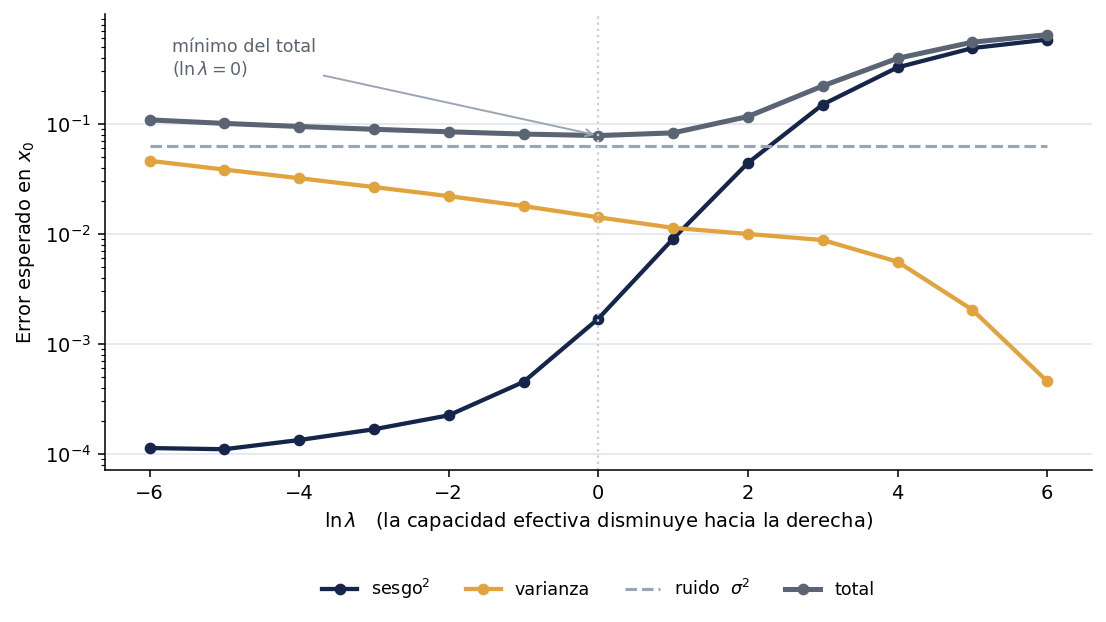

In [5]:
#| label: fig-descomposicion
#| fig-cap: "Sesgo al cuadrado, varianza y ruido en función de la regularización."
eje = LOG_LAMBDAS

fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)
ax.plot(eje, sesgo2, "o-", lw=2.2, ms=5, color="#16264A", label=r"sesgo$^2$")
ax.plot(eje, varianza, "o-", lw=2.2, ms=5, color="#E0A33E", label="varianza")
ax.plot(eje, ruido, "--", lw=1.6, color="#9AA5B5", label=r"ruido  $\sigma^2$")
ax.plot(eje, total, "o-", lw=2.6, ms=5, color="#5B6472", label="total")

mejor = eje[int(np.argmin(total))]
ax.axvline(mejor, color="#C8D0DA", ls=":", lw=1.2)
ax.annotate(f"mínimo del total\n($\\ln\\lambda = {mejor:.0f}$)",
            xy=(mejor, total.min()), xytext=(eje[0] + 0.3, 0.28),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xlabel(r"$\ln\lambda$   (la capacidad efectiva disminuye hacia la derecha)")
ax.set_ylabel(r"Error esperado en $x_0$")
ax.set_xticks(eje[::2])
ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
# La leyenda va bajo el eje: dentro del marco chocaba con la anotación.
ax.legend(frameon=False, ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.20), fontsize=9)

fig.tight_layout()
fig.savefig("descomposicion_sesgo_varianza.png", dpi=200, bbox_inches="tight")
plt.show()

**Escala logarítmica en el eje vertical**, porque los tres términos recorren
cuatro órdenes de magnitud y en escala lineal las curvas del sesgo y del ruido
serían dos líneas pegadas al eje.

**Ojo con la orientación.** El eje horizontal es $\ln\lambda$: hacia la derecha
hay *más* regularización y por lo tanto *menos* capacidad efectiva. La figura
está espejada respecto de la curva en U de la semana 1, donde la capacidad crecía
hacia la derecha. El mínimo sigue donde estaba; lo que cambió es de qué lado
queda cada exceso.

Lo que hay que leer:

1. **El sesgo crece con $\lambda$**, de $1{,}1\times10^{-4}$ a $0{,}58$. Con
   $\lambda$ grande los coeficientes están aplastados, el modelo promedio es casi
   plano y no puede seguir al seno: se equivoca siempre igual.
2. **La varianza decrece con $\lambda$**, de $0{,}046$ a $0{,}0005$. Es la
   contraria exacta, y por la razón de la lámina «El compromiso»: la libertad que
   permite seguir a $f$ es la que permite seguir a $\varepsilon$.
3. **El total tiene su mínimo en $\ln\lambda = 0$**, donde ninguno de los dos
   términos está en el suyo. Ese es el compromiso, medido.
4. **El ruido es plano.** Ninguna elección de $\lambda$ lo toca, y el total nunca
   baja de él.
5. **Y los 25 parámetros no se movieron nunca.** Toda la curva en U se recorrió
   sin agregar ni quitar un solo coeficiente.

## 6. El piso, y por qué conviene conocerlo

El mínimo del total no es cero: no puede serlo, porque $\sigma^2$ está sumando
siempre. Conviene ver qué fracción del error del mejor modelo es irreducible.

In [6]:
i_mejor = int(np.argmin(total))
fraccion = ruido[i_mejor] / total[i_mejor]

print(f"Mejor lambda:               exp({LOG_LAMBDAS[i_mejor]:.0f}) = {LAMBDAS[i_mejor]:.3f}")
print(f"Error total:                {total[i_mejor]:.4f}")
print(f"De eso, ruido irreducible:  {ruido[i_mejor]:.4f}  ({100*fraccion:.0f} %)")
print(f"Margen de mejora real:      {total[i_mejor] - ruido[i_mejor]:.4f}")

Mejor lambda:               exp(0) = 1.000
Error total:                0.0784
De eso, ruido irreducible:  0.0625  (80 %)
Margen de mejora real:      0.0159


Casi todo el error del mejor modelo **es ruido**. Un artículo que persiguiera
mejoras dentro de ese margen estaría persiguiendo algo que no existe.

En un problema real $\sigma^2$ no se conoce, pero muchas veces se puede acotar:
con mediciones repetidas del mismo caso, o con el acuerdo entre anotadores si
las etiquetas son juicios humanos. **Si dos expertos coinciden en el 85 % de los
casos, no espere un clasificador del 95 %.**

## 7. Bitácora

**Decisiones tomadas**

1. *Se barre $\lambda$ y no el grado del polinomio.* Es la decisión que gobierna
   todo lo demás, y se toma por dos razones. La primera es de medición: barriendo
   el grado, el sesgo se desploma varios órdenes de magnitud en cuanto la familia
   alcanza a representar el seno, y queda por debajo del piso de Monte Carlo
   —momento en que la curva graficada deja de medir sesgo y pasa a medir la
   incertidumbre del propio promedio—. Con $\lambda$ la capacidad varía de forma
   continua y el sesgo se mantiene medible en todo el eje; la sección 8 lo
   verifica. La segunda es pedagógica: el número de parámetros queda **fijo en
   25** durante todo el barrido, de modo que la curva en U aparece sin agregar ni
   quitar un coeficiente. Es la afirmación de la lámina «Capacidad» —que la
   capacidad no es el número de parámetros— convertida en medición.
2. *Base gaussiana de 24 funciones, y $n=25$.* Es el diseño de Bishop (2006),
   §3.2, figura 3.5, con sus mismos números. Se sigue un ejemplo publicado y
   probado en vez de inventar uno.
3. *3000 réplicas, no 300.* El promedio sobre réplicas tiene incertidumbre
   $\operatorname{Var}/R$, y esa cantidad es el piso por debajo del cual el sesgo
   medido sería ruido de simulación. Resolver un sistema de $25\times25$ es lo
   bastante barato como para que subir a 3000 no cueste nada apreciable, y a
   cambio el piso baja diez veces. La sección 8 comprueba el margen.
4. *Rango $\ln\lambda$ de $-6$ a $6$.* Cubre desde el ajuste prácticamente libre
   hasta el modelo casi constante. Más a la izquierda el sesgo se hunde bajo el
   piso de Monte Carlo y se reproduciría el problema del barrido por grado.
5. *Escala logarítmica en el eje vertical.* Los tres términos recorren cuatro
   órdenes de magnitud. En escala lineal, el sesgo y el ruido serían dos líneas
   pegadas al eje.
6. *Descomposición en un punto y no integrada.* En $x_0$ la identidad es exacta y
   se puede verificar término a término. Integrada sobre $x$ también vale, pero
   la verificación exigiría cuadratura y el error de cuadratura se confundiría
   con el error de la identidad.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró estimar el sesgo comparando contra el promedio de $y$ en vez de
contra $f(x_0)$. **Se descartó** porque el promedio de $y$ incluye el ruido, y
entonces el término de sesgo absorbería parte de $\sigma^2$: la descomposición
seguiría sumando bien pero los tres términos ya no significarían lo que dice la
clase. Aquí se puede usar $f$ porque la conocemos; en un problema real no, y esa
es precisamente la razón de que la descomposición sea una herramienta conceptual
y no un procedimiento.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

Tres comprobaciones. La primera es la que importa: que la identidad de la clase
se cumpla numéricamente. Se calcula el error total **de forma independiente**
—simulando observaciones nuevas en $x_0$— y se compara con la suma de los tres
términos. Las otras dos protegen la lectura de la figura: que el sesgo medido
esté por encima del piso de Monte Carlo, y que la conclusión no dependa del
número de réplicas.

In [7]:
# Error total medido directamente, sin usar la descomposición.
r = np.random.default_rng(SEMILLA + 1000)
y0_nuevos = f_verdadera(X0) + r.normal(0, SIGMA, 200_000)
total_directo = np.array([
    np.mean((y0_nuevos[:, None] - predicciones[:, i][None, :]) ** 2)
    for i in range(len(LAMBDAS))
])

error_relativo = np.abs(total_directo - total) / total
print(f"{'ln lambda':>10} {'suma de los 3':>15} {'medido directo':>16} {'error rel.':>12}")
print("-" * 56)
for i, ll in enumerate(LOG_LAMBDAS):
    print(f"{ll:>10.0f} {total[i]:>15.4f} {total_directo[i]:>16.4f} {error_relativo[i]:>12.2%}")

assert np.all(error_relativo < 0.02), "La descomposición no reproduce el error total."
print("\nLa identidad sesgo^2 + varianza + ruido = error total se cumple (< 2 %).")

 ln lambda   suma de los 3   medido directo   error rel.
--------------------------------------------------------
        -6          0.1088           0.1088        0.01%
        -5          0.1011           0.1011        0.01%
        -4          0.0947           0.0947        0.01%
        -3          0.0894           0.0894        0.01%
        -2          0.0848           0.0848        0.00%
        -1          0.0809           0.0809        0.00%
         0          0.0784           0.0783        0.03%
         1          0.0829           0.0828        0.10%
         2          0.1167           0.1165        0.18%
         3          0.2214           0.2210        0.18%
         4          0.3945           0.3939        0.15%
         5          0.5533           0.5526        0.13%
         6          0.6470           0.6462        0.12%

La identidad sesgo^2 + varianza + ruido = error total se cumple (< 2 %).


In [8]:
# ¿El sesgo medido es sesgo, o es ruido de simulación? El promedio sobre réplicas
# tiene varianza Var/R; por debajo de ese piso, la curva del sesgo no mide sesgo.
piso_monte_carlo = varianza / N_REPLICAS
razon = sesgo2 / piso_monte_carlo

print(f"{'ln lambda':>10} {'sesgo^2':>12} {'piso Var/R':>13} {'razón':>10}")
print("-" * 48)
for i, ll in enumerate(LOG_LAMBDAS):
    print(f"{ll:>10.0f} {sesgo2[i]:>12.5f} {piso_monte_carlo[i]:>13.2e} {razon[i]:>10.1f}")

assert razon.min() > 3, (
    f"El sesgo medido se acerca al piso de Monte Carlo (razón {razon.min():.1f}): "
    "suba N_REPLICAS o recorte el rango de lambda.")
print(f"\nMargen mínimo sobre el piso: {razon.min():.1f}x. La curva del sesgo mide sesgo.")

# ¿Bastan las réplicas? Se recalcula con la mitad y se compara el lambda óptimo.
mitad = predicciones[:N_REPLICAS // 2]
total_mitad = ((f_verdadera(X0) - mitad.mean(axis=0)) ** 2
               + mitad.var(axis=0, ddof=0) + SIGMA ** 2)

l_todas = LOG_LAMBDAS[int(np.argmin(total))]
l_mitad = LOG_LAMBDAS[int(np.argmin(total_mitad))]
print(f"ln lambda óptimo con {N_REPLICAS} réplicas: {l_todas:.0f}")
print(f"ln lambda óptimo con {N_REPLICAS // 2} réplicas: {l_mitad:.0f}")
assert l_todas == l_mitad, "El resultado depende del número de réplicas: use más."
print("La conclusión es estable al reducir a la mitad las réplicas.")

 ln lambda      sesgo^2    piso Var/R      razón
------------------------------------------------
        -6      0.00011      1.54e-05        7.4
        -5      0.00011      1.28e-05        8.6
        -4      0.00013      1.07e-05       12.5
        -3      0.00017      8.90e-06       18.9
        -2      0.00022      7.35e-06       30.5
        -1      0.00045      5.98e-06       75.6
         0      0.00170      4.72e-06      359.8
         1      0.00905      3.79e-06     2389.6
         2      0.04419      3.33e-06    13266.4
         3      0.15011      2.93e-06    51163.8
         4      0.32641      1.86e-06   175142.1
         5      0.48878      6.82e-07   716748.1
         6      0.58402      1.53e-07  3823430.1

Margen mínimo sobre el piso: 7.4x. La curva del sesgo mide sesgo.
ln lambda óptimo con 3000 réplicas: 0
ln lambda óptimo con 1500 réplicas: 0
La conclusión es estable al reducir a la mitad las réplicas.
